# Predicting Concrete Compressive Strength with Neural Networks

**Hayden Willen** | Machine Learning II | University of Virginia School of Data Science

This project predicts the compressive strength of concrete (in MPa) from its mix ingredients and curing age. I build a neural network in PyTorch, replicate it with scikit-learn's `MLPRegressor`, and compare both against a support vector machine and linear regression using 5-fold cross-validation.

The inputs are cement, blast furnace slag, fly ash, water, superplasticizer, coarse aggregate, fine aggregate and age. The data has 1,030 concrete mixes.

Based on I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," *Cement and Concrete Research*, Vol. 28, No. 12, pp. 1797-1808 (1998). [Paper](https://doi.org/10.1016/S0008-8846(98)00165-3) | [Dataset](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength)

## Approach

I compare three models: a neural network, a support vector machine (SVR), and linear regression. All models use fixed settings with no tuning. I score each with 5-fold cross-validation, and wIe perform all preprocessing within each fold to avoid data leakage.

## 1. Analysis Plan

Before writing code, I planned four things.

- **Descriptive analysis.** Which summaries and plots show how each input relates to strength.
- **Data preprocessing.** Which steps a neural network needs.
- **Model configuration.** Which cost function and output activation fit a regression target.
- **Performance evaluation.** How to run k-fold cross-validation and report averaged results.

#### Descriptive analysis

I will start by checking data quality. That means counting missing values, duplicate rows, and zeros in each column. The zeros in slag, fly_ash, and superplasticizer are expected, because they mean the ingredient was not used in that mix, so I will treat them as real values rather than missing data.
Next, I will summarize each variable with describe(), which gives the mean, standard deviation, range, and quartiles. We will also plot histograms and compute skewness to understand each distribution's shape and spot heavy skew or outliers, particularly in age.

To study how each input relates to the outcome, I will plot each feature against strength with a fitted regression line. This shows the direction and rough linearity of each relationship. Because age takes only 14 distinct values, I will also group strength by age and draw a boxplot, which shows the nonlinear curing pattern more clearly.
Finally, I will draw a correlation heatmap. It shows which inputs are most linearly related to strength and whether any inputs are strongly correlated with each other, such as water and superplasticizer.

#### Data preprocessing

The dataset has no missing values, so no imputation is needed. It has 25 duplicate rows, which I chose to keep because repeated mix designs are plausible in lab testing. I acknowledge that identical rows could land in both a training and a test fold, which may slightly inflate performance.

The features are on very different scales: age ranges from 1 to 365, while coarse_agg ranges from roughly 800 to 1145. Neural networks trained with gradient descent are sensitive to this, so we will standardize every feature to mean 0 and standard deviation 1 with StandardScaler.

To avoid data leakage, we will fit the scaler on the training fold only and then apply it to the test fold. I will refit it from scratch inside every fold, so the test data never influences the scaling.
After scaling, we will convert the features and target to float32 tensors and reshape the target to a column vector so it matches the network's output shape. I will leave the target unscaled so that prediction errors can be read directly in MPa.

#### Model configuration

Compressive strength is a continuous outcome measured in MPa, ranging from about 2 to 83, so this is a regression problem rather than a classification problem.

For that reason, the output layer will be a single neuron with no activation function. Activations like sigmoid or softmax would squash predictions into a probability range, which is inappropriate for an unbounded continuous target.
The cost function will be Mean Squared Error (nn.MSELoss), the standard loss for regression. It penalizes large errors more heavily and corresponds to maximum likelihood estimation under Gaussian noise.

The network will have two hidden layers going from 8 inputs to 64 to 32 units and then to one output. Both hidden layers use ReLU activations, which let the model capture nonlinear effects such as the relationship between strength and curing age.

I will train with Adam at a learning rate of 0.001, a batch size of 32 loaded through DataLoader, and 300 epochs. As the assignment instructs, these settings are fixed and not tuned.

#### Performance evaluation

I will evaluate performance with 5-fold cross-validation, using KFold with shuffling enabled and a random seed of 42. Shuffling matters because the rows are ordered by mix design. With 1,030 observations, each fold trains on about 824 rows and tests on about 206.

Within each fold, I will split the data, fit the scaler on the training portion, create a new model so that no weights carry over between folds, train it, and then predict on the held-out fold. For each fold I will compute MSE, RMSE, MAE, and R².

My final result is the mean and standard deviation of each metric across the five folds. The mean is the expected performance, and the standard deviation shows how stable the model is across different splits of the data.

The same seed and fold splits will be reused for the scikit-learn MLP, the SVM, and Linear Regression, so that every model is evaluated on identical data partitions and the comparison is fair.

## 2. Exploratory Data Analysis

I load the data, check its quality, and look at how each input relates to strength.

In [1]:

import numpy as np
import pandas as pd


import matplotlib.pyplot as plt
import seaborn as sns


import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)


In [2]:
df = pd.read_excel("data/Concrete_Data.xls")

df.columns = [
    "cement", "slag", "fly_ash", "water",
    "superplasticizer", "coarse_agg", "fine_agg", "age",
    "strength",
]

print(df.shape)
df.head()


(1030, 9)


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [3]:
X = df.drop(columns="strength").values 
y = df["strength"].values  

print(X.shape, y.shape)

(1030, 8) (1030,)


In [4]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nZeros per column:")
print((df == 0).sum())


Missing values: 0
Duplicate rows: 25

Zeros per column:
cement                0
slag                466
fly_ash             566
water                 0
superplasticizer    379
coarse_agg            0
fine_agg              0
age                   0
strength              0
dtype: int64


In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
fly_ash,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
water,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
coarse_agg,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
fine_agg,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


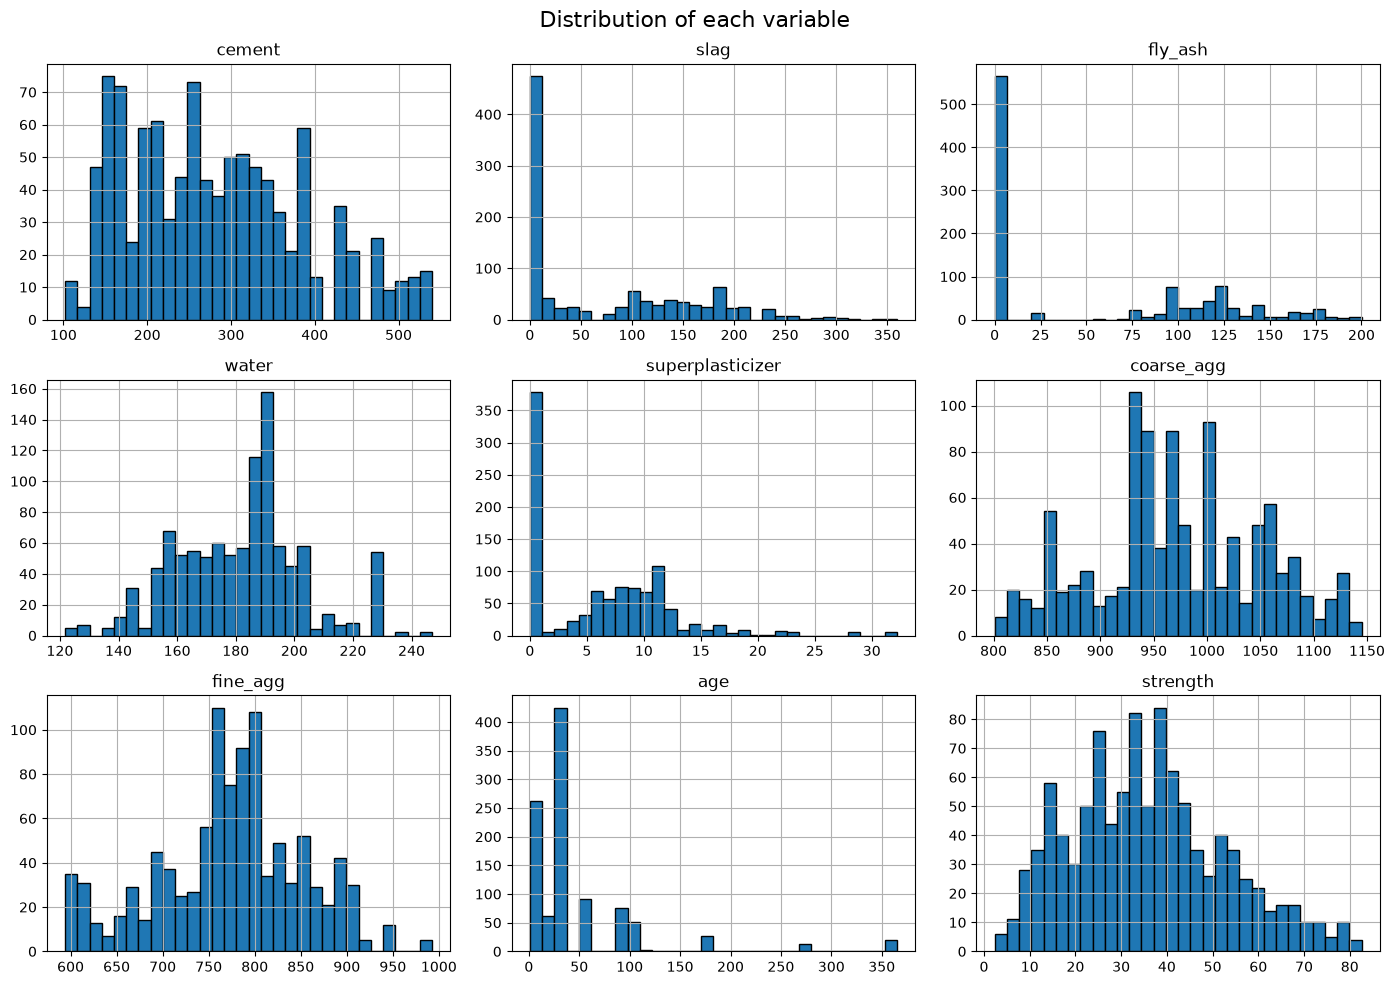

Skewness:
cement              0.51
slag                0.80
fly_ash             0.54
water               0.07
superplasticizer    0.91
coarse_agg         -0.04
fine_agg           -0.25
age                 3.27
strength            0.42
dtype: float64


In [6]:
df.hist(bins=30, figsize=(14, 10), edgecolor="black")
plt.suptitle("Distribution of each variable", fontsize=16)
plt.tight_layout()
plt.show()

print("Skewness:")
print(df.skew().round(2))


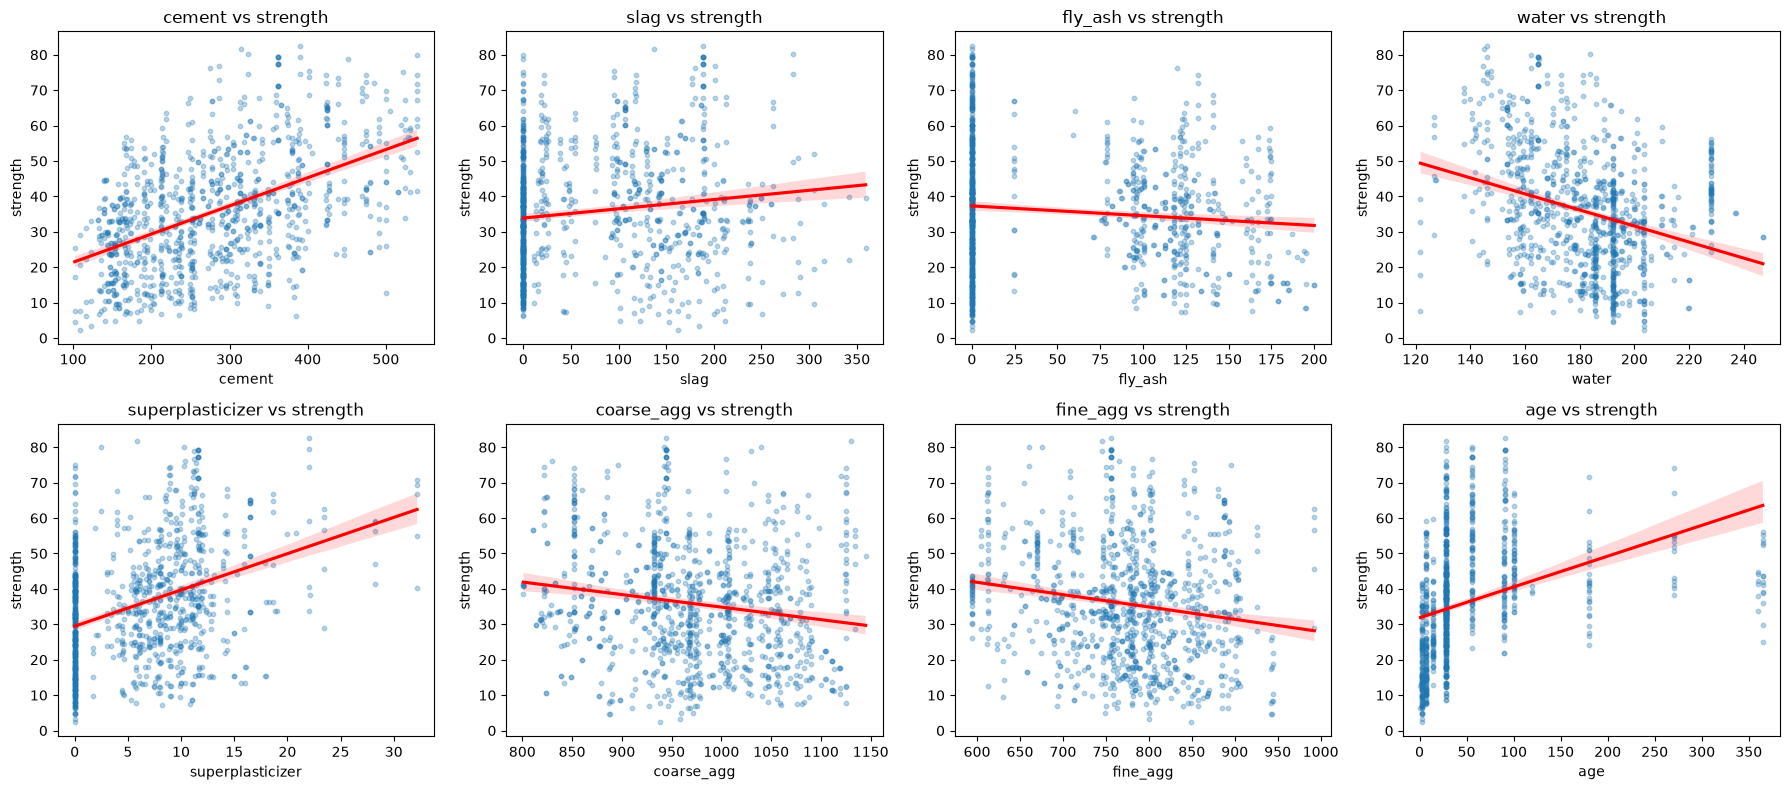

In [7]:
features = df.columns.drop("strength")

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, features):
    sns.regplot(data=df, x=col, y="strength", ax=ax,
                scatter_kws={"alpha": 0.3, "s": 10},
                line_kws={"color": "red"})
    ax.set_title(f"{col} vs strength")
plt.tight_layout()
plt.show()


     mean  count
age             
1     9.5      2
3    19.0    134
7    26.1    126
14   28.8     62
28   36.7    425
56   51.9     91
90   40.5     54
91   69.8     22
100  47.7     52
120  39.6      3
180  41.7     26
270  51.3     13
360  40.7      6
365  43.6     14


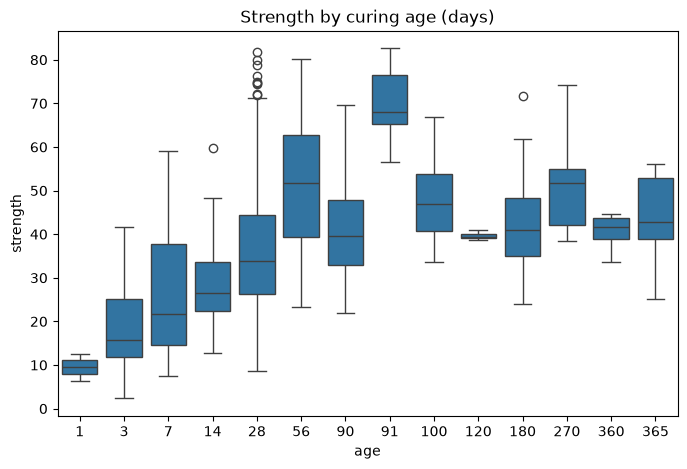

In [8]:
age_means = df.groupby("age")["strength"].agg(["mean", "count"]).round(1)
print(age_means)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="age", y="strength")
plt.title("Strength by curing age (days)")
plt.show()


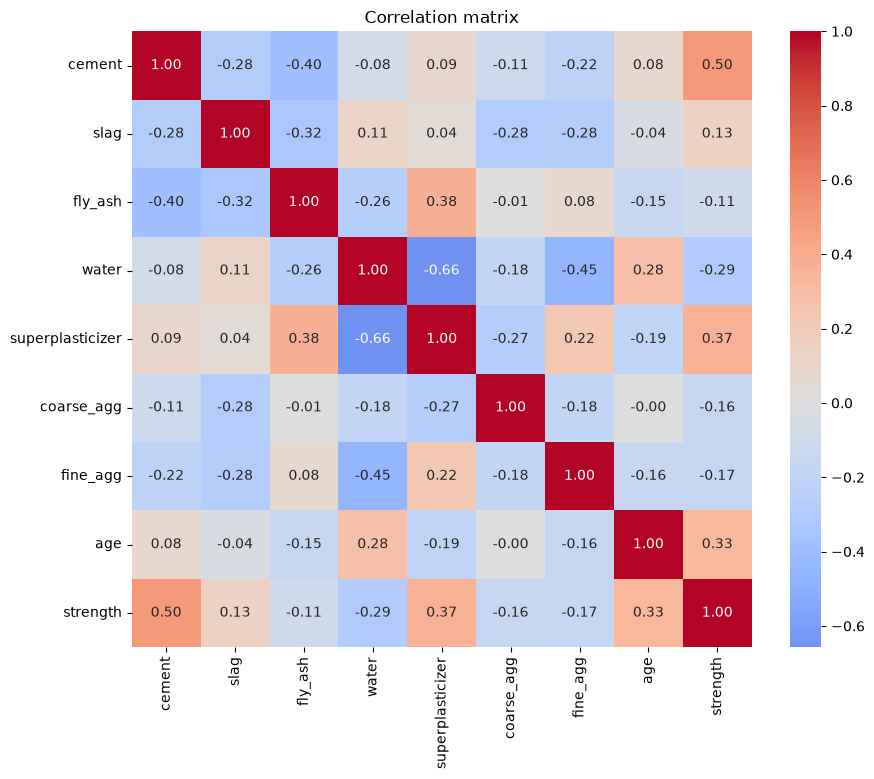

strength            1.00
cement              0.50
superplasticizer    0.37
age                 0.33
slag                0.13
fly_ash            -0.11
coarse_agg         -0.16
fine_agg           -0.17
water              -0.29
Name: strength, dtype: float64


In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

print(df.corr()["strength"].sort_values(ascending=False).round(2))


## What I found

Cement has the strongest link to strength (r = 0.50), followed by superplasticizer (0.37) and age (0.33). Water has the strongest negative link (r = -0.29), so wetter mixes tend to be weaker. Strength rises quickly over the first 28 days and gains little after about 56 days, which is a curved pattern a straight line cannot capture
Slag, fly ash and superplasticizer are zero in many mixes, which means those ingredients were simply left out.

## 3. Neural Network in PyTorch

The network is a class that inherits from `nn.Module`, with `nn.Linear` layers, `nn.ReLU` activations in the hidden layers and a single linear output for regression. It trains with `nn.MSELoss` and the Adam optimizer, using a `DataLoader` for mini-batches. The scaler is refit inside every fold.

In [10]:
K = 5
kf = KFold(n_splits=K, shuffle=True, random_state=SEED)

N_EPOCHS   = 300
BATCH_SIZE = 32
LR         = 0.001


In [11]:
class ConcreteNet(nn.Module):
    def __init__(self, n_inputs, hidden1=64, hidden2=32):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(n_inputs, hidden1),
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Linear(hidden2, 1),
        )

    def forward(self, x):
        return self.model(x)


In [12]:
nn_results = []

for fold, (train_idx, test_idx) in enumerate(kf.split(X), start=1):
    torch.manual_seed(SEED + fold)
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test  = scaler.transform(X_test)

    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
    X_test_t  = torch.tensor(X_test,  dtype=torch.float32)

    train_loader = DataLoader(TensorDataset(X_train_t, y_train_t),
                              batch_size=BATCH_SIZE, shuffle=True)

    model     = ConcreteNet(n_inputs=X.shape[1])
    loss_fn   = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    for epoch in range(N_EPOCHS):
        model.train()
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        preds = model(X_test_t).numpy().ravel()

        
    mse  = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_test, preds)
    r2   = r2_score(y_test, preds)
    nn_results.append({"fold": fold, "MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2})
    print(f"Fold {fold}: MSE={mse:.2f}  RMSE={rmse:.2f}  MAE={mae:.2f}  R²={r2:.3f}")



Fold 1: MSE=37.16  RMSE=6.10  MAE=4.25  R²=0.856
Fold 2: MSE=33.57  RMSE=5.79  MAE=4.19  R²=0.900
Fold 3: MSE=30.92  RMSE=5.56  MAE=3.90  R²=0.891
Fold 4: MSE=28.41  RMSE=5.33  MAE=3.88  R²=0.899
Fold 5: MSE=22.88  RMSE=4.78  MAE=3.59  R²=0.903


In [13]:
nn_df = pd.DataFrame(nn_results)
print(nn_df.round(3))
print("\nMean ± std across folds:")
print(nn_df[["MSE", "RMSE", "MAE", "R2"]].agg(["mean", "std"]).round(3))


   fold     MSE   RMSE    MAE     R2
0     1  37.156  6.096  4.254  0.856
1     2  33.567  5.794  4.195  0.900
2     3  30.916  5.560  3.898  0.891
3     4  28.406  5.330  3.880  0.899
4     5  22.877  4.783  3.587  0.903

Mean ± std across folds:
         MSE   RMSE    MAE     R2
mean  30.584  5.512  3.963  0.890
std    5.393  0.497  0.270  0.019


## 4. Replication with scikit-learn

I rebuilt the same network with scikit-learn's `MLPRegressor`, using the same layers, learning rate, batch size, epochs and folds, so the two versions can be compared fairly.

In [14]:
from sklearn.model_selection import cross_validate

mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        learning_rate_init=LR,
        batch_size=BATCH_SIZE,
        max_iter=N_EPOCHS,
        alpha=0.0,
        shuffle=True,
        random_state=SEED,
    ),
)

scoring = {
    "MSE":  "neg_mean_squared_error",
    "RMSE": "neg_root_mean_squared_error",
    "MAE":  "neg_mean_absolute_error",
    "R2":   "r2",
}

mlp_cv = cross_validate(mlp, X, y, cv=kf, scoring=scoring)


/Users/haydenwillen/Desktop/Machine Learning II/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/haydenwillen/Desktop/Machine Learning II/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/haydenwillen/Desktop/Machine Learning II/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/haydenwillen/Desktop/Machine Learning II/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maxim

In [15]:
mlp_df = pd.DataFrame({
    "fold": range(1, K + 1),
    "MSE":  -mlp_cv["test_MSE"],
    "RMSE": -mlp_cv["test_RMSE"],
    "MAE":  -mlp_cv["test_MAE"],
    "R2":    mlp_cv["test_R2"],
})
print(mlp_df.round(3))
print("\nMean ± std across folds:")
print(mlp_df[["MSE", "RMSE", "MAE", "R2"]].agg(["mean", "std"]).round(3))


   fold     MSE   RMSE    MAE     R2
0     1  31.501  5.613  3.954  0.878
1     2  34.253  5.853  4.150  0.898
2     3  25.909  5.090  3.531  0.908
3     4  30.408  5.514  4.014  0.892
4     5  26.879  5.184  3.876  0.886

Mean ± std across folds:
         MSE   RMSE    MAE     R2
mean  29.790  5.451  3.905  0.892
std    3.419  0.313  0.232  0.012


## 5. Model Comparison

I fit an SVR with an RBF kernel and a linear regression on the same folds and compare all four models on MSE, RMSE, MAE and R².

In [16]:
def run_cv(model):
    """Run k-fold CV on a scaler+model pipeline; return a per-fold results table."""
    pipe = make_pipeline(StandardScaler(), model)
    cv = cross_validate(pipe, X, y, cv=kf, scoring=scoring)
    return pd.DataFrame({
        "fold": range(1, K + 1),
        "MSE":  -cv["test_MSE"],
        "RMSE": -cv["test_RMSE"],
        "MAE":  -cv["test_MAE"],
        "R2":    cv["test_R2"],
    })

svr_df = run_cv(SVR(kernel="rbf", C=100, epsilon=1.0))
lr_df  = run_cv(LinearRegression())

print("SVR:\n", svr_df.round(3))
print("\nLinear Regression:\n", lr_df.round(3))


SVR:
    fold     MSE   RMSE    MAE     R2
0     1  33.346  5.775  4.078  0.871
1     2  39.729  6.303  4.188  0.881
2     3  40.284  6.347  4.155  0.858
3     4  30.124  5.489  3.958  0.893
4     5  31.009  5.569  4.211  0.869

Linear Regression:
    fold      MSE    RMSE    MAE     R2
0     1   95.975   9.797  7.745  0.628
1     2  135.908  11.658  9.243  0.594
2     3  125.348  11.196  9.001  0.557
3     4   90.942   9.536  7.539  0.677
4     5  106.881  10.338  8.183  0.547


In [17]:
all_results = {
    "Neural Net (PyTorch)":  nn_df,
    "Neural Net (sklearn)":  mlp_df,
    "SVR (RBF)":             svr_df,
    "Linear Regression":     lr_df,
}

summary = pd.DataFrame({
    name: df_[["MSE", "RMSE", "MAE", "R2"]].mean()
    for name, df_ in all_results.items()
}).T

summary["MSE std"] = [df_["MSE"].std() for df_ in all_results.values()]
print(summary.sort_values("MSE").round(3))


                          MSE    RMSE    MAE     R2  MSE std
Neural Net (sklearn)   29.790   5.451  3.905  0.892    3.419
Neural Net (PyTorch)   30.584   5.512  3.963  0.890    5.393
SVR (RBF)              34.899   5.896  4.118  0.874    4.813
Linear Regression     111.011  10.505  8.342  0.601   19.179


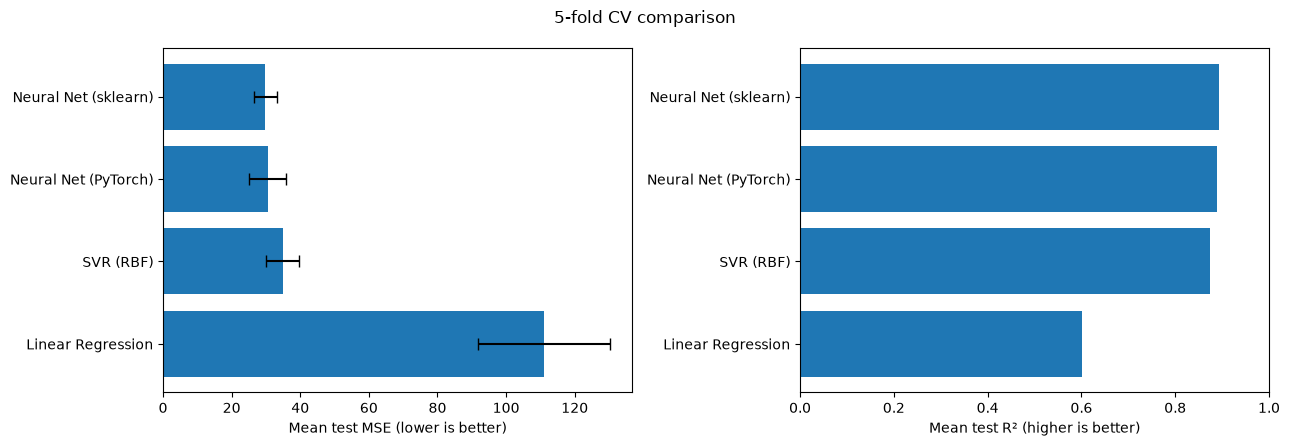

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

summary_sorted = summary.sort_values("MSE")
axes[0].barh(summary_sorted.index, summary_sorted["MSE"],
             xerr=summary_sorted["MSE std"], capsize=4)
axes[0].set_xlabel("Mean test MSE (lower is better)")
axes[0].invert_yaxis()

axes[1].barh(summary_sorted.index, summary_sorted["R2"])
axes[1].set_xlabel("Mean test R² (higher is better)")
axes[1].set_xlim(0, 1)
axes[1].invert_yaxis()

plt.suptitle(f"{K}-fold CV comparison")
plt.tight_layout()
plt.show()


The two neural networks performed almost the same, with a mean MSE of 30.58 for PyTorch and 29.79 for MLPRegressor, since they used the same architecture and training settings. The SVR with an RBF kernel came close, with an MSE of about 34.9 and an R² of about 0.87. Linear regression performed much worse, with an MSE of about 111 and an R² of about 0.60, almost four times the neural networks' error. My descriptive analysis explains this gap. Strength rises quickly in the first month of curing and then levels off, and it depends on combinations of ingredients rather than any single feature, which a straight line cannot capture, but the ReLU layers and RBF kernel can. Overall, the non-linear models clearly fit this problem better, and the neural network had a slight edge over SVR.